# DFND: three probes on the same tetrahedron

**Question:** does the current DFND implementation reproduce the independently
justified clearances and distinguish residence from passage?

Start with [the system and its predictions](system.ipynb). This notebook reads
the same frozen input and its committed independent reference; it does not
depend on another notebook's live variables. Run all cells from this case
directory in a fresh kernel. No original provider or server is executed.

The study inspects raw records and the query's reported compatibility buckets.
Those buckets are a current reporting surface, not a claim of full adoption
of the future canonical Topography contract.

In [1]:
import hashlib
import html
import json
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from pyunitwizard import QuantityRecord

import topomt as tmt
from topomt import pyunitwizard as puw
from topomt.dfnd import DelaunayFlowNetwork

input_bytes = Path('artifacts/regular_tetrahedron_v1/input.json').read_bytes()
reference_bytes = Path('artifacts/native_study_v1/system_reference.json').read_bytes()
fixture = json.loads(input_bytes)
reference = json.loads(reference_bytes)
assert reference['input_sha256'] == hashlib.sha256(input_bytes).hexdigest()


def decode(record, field, unit):
    return QuantityRecord.from_dict(record).to_quantity(field=field, unit=unit)


def input_quantity(field):
    return decode(fixture[field], field, 'angstroms')


def reference_value(field, unit='angstroms'):
    return float(puw.get_value(decode(reference['reference'][field], field, unit), to_unit=unit))


def qrecord(value, unit, field):
    return QuantityRecord.from_quantity(puw.quantity(value, unit), field=field).to_dict()


def length_values(value):
    return np.asarray(puw.get_value(puw.quantity(value, 'nm'), to_unit='angstroms'))


def volume_value(value):
    return float(puw.get_value(puw.quantity(value, 'nm**3'), to_unit='angstroms**3'))


coords = np.asarray(puw.get_value(input_quantity('coordinates'), to_unit='angstroms'))
radii = np.asarray(puw.get_value(input_quantity('atom_radii'), to_unit='angstroms'))
probes = np.asarray(puw.get_value(input_quantity('anchor_probes'), to_unit='angstroms'))
probe_sweep = np.asarray(puw.get_value(input_quantity('probe_sweep'), to_unit='angstroms'))
atol = float(puw.get_value(decode(reference['tolerances']['clearance_absolute'],
                                'clearance_absolute', 'angstroms'), to_unit='angstroms'))
expected_residence = reference_value('residence_clearance')
expected_face = reference_value('face_clearance')
expected_hull = reference_value('cell_hull_volume', 'angstroms**3')

## Build once; preserve the minimal component

We provide coordinates and radii explicitly, with the frozen epsilon.
Every main query uses `min_size=0`, retaining this one-cell example. Physical
residence/permeability tolerances remain zero; transit policy is
`with_connectors`, intrusion policy `flag_only` and dry adjacency `face`.

Network primitive arrays and raw record volumes use nm and nm³ internally.
We convert with explicit PyUnitWizard units for all displayed measurements
and keep quantities in the exported report.

In [2]:
network = DelaunayFlowNetwork.from_coordinates_and_radii(
    input_quantity('coordinates'), input_quantity('atom_radii'),
    epsilon=input_quantity('epsilon'),
)
assert network.n_tetrahedra == 1
observed_residence = length_values(network.tetra_residence)
observed_faces = length_values(network.face_r_gates_per_tet_face)
np.testing.assert_allclose(observed_residence, expected_residence, rtol=0, atol=atol)
np.testing.assert_allclose(observed_faces, expected_face, rtol=0, atol=atol)
display(Markdown(
    '| Primitive | Independent (Å) | DFND (Å) | Maximum absolute error (Å) |\n'
    '|---|---:|---:|---:|\n'
    f'| Residence | {expected_residence:.9f} | {observed_residence[0]:.9f} | '
    f'{np.max(np.abs(observed_residence-expected_residence)):.3g} |\n'
    f'| Four face gates | {expected_face:.9f} | {observed_faces.mean():.9f} | '
    f'{np.max(np.abs(observed_faces-expected_face)):.3g} |'
))


def observe(probe, min_size=0):
    result = network.get_topography(
        probe_radius=puw.quantity(float(probe), 'angstroms'), min_size=min_size,
        transit_policy='with_connectors', gate_intrusion_policy='flag_only',
        residence_tolerance=puw.quantity(0.0, 'angstroms'),
        permeability_tolerance=puw.quantity(0.0, 'angstroms'), dry_adjacency='face',
    )
    cell = result['raw']['tetrahedra'][0]
    components = result['raw']['wet_components']
    observation = {
        'probe_radius': qrecord(float(probe), 'angstroms', 'probe_radius'),
        'resident': cell['residence_state'] == 'resident',
        'permeable_faces': int(cell['n_permeable_contacts']),
        'family': components[0]['family'] if components else 'non_resident',
        'raw_component_count': len(components),
        'external_links': sum(int(c['n_external_links']) for c in components),
        'local_class': cell['local_class'], 'transit_role': cell['transit_role'],
        'reported_counts': {key: len(value) for key, value in result['wet'].items()},
        'cell_hull_volume': qrecord(volume_value(cell['volume_topological']),
                                    'angstroms**3', 'cell_hull_volume'),
        'solvent_volume_estimate': qrecord(volume_value(cell['volume_solvent_estimate']),
                                           'angstroms**3', 'solvent_volume_estimate'),
    }
    return observation, result


def show_experiment(index):
    probe = float(probes[index])
    observed, result = observe(probe)
    expected = reference['experiments'][index]
    assert observed['resident'] == expected['resident']
    assert observed['permeable_faces'] == expected['permeable_faces']
    assert observed['raw_component_count'] == int(expected['resident'])
    np.testing.assert_allclose(volume_value(result['raw']['tetrahedra'][0]['volume_topological']),
                               expected_hull, rtol=reference['tolerances']['hull_volume_relative'])
    display(Markdown(
        '| Observable | Expected / interpretation | Observed |\n|---|---|---|\n'
        f"| Residence | {expected['resident']} | {observed['resident']} |\n"
        f"| Permeable faces | {expected['permeable_faces']} | {observed['permeable_faces']} |\n"
        f"| Raw wet components | {int(expected['resident'])} | {observed['raw_component_count']} |\n"
        f"| Current family | Inspect DFND classification | {observed['family']} |\n"
        f"| Exterior-link clusters | Inspect grouping | {observed['external_links']} |"
    ))
    return observed, result

| Primitive | Independent (Å) | DFND (Å) | Maximum absolute error (Å) |
|---|---:|---:|---:|
| Residence | 1.545573909 | 1.545573909 | 0 |
| Four face gates | 1.359956427 | 1.359956427 | 1.11e-15 |

## Probe 1.2 Å: residence and face passage

The probe is smaller than both reference clearances. We expect a resident
node and four permeable exterior faces. The query should expose the component
as fully open (`percolating`), rather than call it a bounded pocket.

In [3]:
first, first_result = show_experiment(0)
assert first['family'] == 'percolating' and first['external_links'] == 1
assert first['reported_counts']['percolatings'] == 1
assert first['reported_counts']['pockets'] == 0

| Observable | Expected / interpretation | Observed |
|---|---|---|
| Residence | True | True |
| Permeable faces | 4 | 4 |
| Raw wet components | 1 | 1 |
| Current family | Inspect DFND classification | percolating |
| Exterior-link clusters | Inspect grouping | 1 |

## Probe 1.4 Å: residence with sealed faces

The probe fits inside the tetrahedral gap but exceeds every face clearance.
We expect one resident component with no exterior connection: `void` in the
current query. This closure concerns probe-center space at the specified
radius; the unexpanded four atomic balls are not a sealed material shell.

In [4]:
second, second_result = show_experiment(1)
assert second['family'] == 'void' and second['external_links'] == 0
assert second['reported_counts']['voids'] == 1

| Observable | Expected / interpretation | Observed |
|---|---|---|
| Residence | True | True |
| Permeable faces | 0 | 0 |
| Raw wet components | 1 | 1 |
| Current family | Inspect DFND classification | void |
| Exterior-link clusters | Inspect grouping | 0 |

## Probe 1.7 Å: no resident node in the finite cell

The probe exceeds the residence clearance. We expect no resident wet
component, although the finite tetrahedron and its atom-free space still
exist. This result makes no statement that all exterior space disappeared.

In [5]:
third, third_result = show_experiment(2)
assert third['family'] == 'non_resident' and third['external_links'] == 0
assert sum(third['reported_counts'].values()) == 0
anchors = [first, second, third]

| Observable | Expected / interpretation | Observed |
|---|---|---|
| Residence | False | False |
| Permeable faces | 0 | 0 |
| Raw wet components | 0 | 0 |
| Current family | Inspect DFND classification | non_resident |
| Exterior-link clusters | Inspect grouping | 0 |

## See the three experiments together

The atomic geometry and viewing limits are identical. The colored central
sphere is the test probe: green when it fits at the center, red when it does
not. Dashed edges are geometric guides. Face passage and grouping are read
from the numerical results, not inferred merely from this picture.

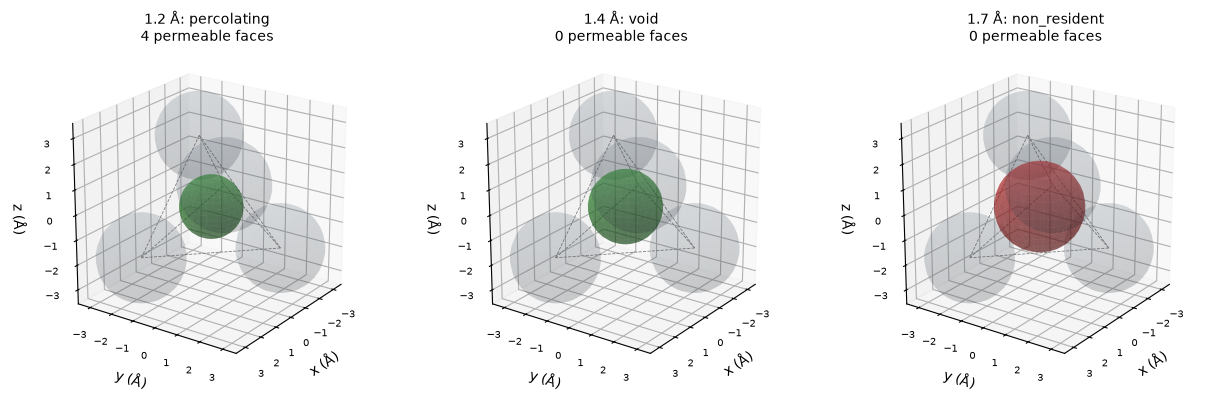

In [6]:
center = coords.mean(axis=0)
azimuth = np.linspace(0, 2*np.pi, 28)
polar = np.linspace(0, np.pi, 18)
sphere = np.array([
    np.outer(np.cos(azimuth), np.sin(polar)),
    np.outer(np.sin(azimuth), np.sin(polar)),
    np.outer(np.ones_like(azimuth), np.cos(polar)),
])
fig = plt.figure(figsize=(12, 4.5))
limit = float(np.max(np.abs(coords-center)) + radii.max())
for column, (probe, observation) in enumerate(zip(probes, anchors), start=1):
    ax = fig.add_subplot(1, 3, column, projection='3d')
    for i, point in enumerate(coords):
        ax.plot_surface(*(point[:, None, None] + radii[i]*sphere),
                        color='slategray', alpha=0.12, linewidth=0)
        for other in coords[:i]:
            ax.plot(*np.stack([point, other]).T, '--', color='gray', linewidth=0.6)
    color = 'tab:green' if observation['resident'] else 'tab:red'
    ax.plot_surface(*(center[:, None, None] + probe*sphere),
                    color=color, alpha=0.45, linewidth=0)
    ax.set(xlim=(center[0]-limit, center[0]+limit),
           ylim=(center[1]-limit, center[1]+limit),
           zlim=(center[2]-limit, center[2]+limit),
           xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)')
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=35)
    ax.tick_params(labelsize=7)
    ax.set_title(f"{probe:.1f} Å: {observation['family']}\n"
                 f"{observation['permeable_faces']} permeable faces", fontsize=10)
fig.subplots_adjust(left=0.02, right=0.98, bottom=0.08, top=0.85, wspace=0.28)
plt.show()

Four permeable exterior faces form **one exterior-link cluster** here.
Percolating components do not thereby acquire four independent physical
mouths. At 1.4 Å the local `resident_transit` label describes participation
in the current graph construction; the zero permeable contacts remain the
evidence for sealed faces. Neither a role label nor graph adjacency alone
certifies continuous physical navigation in a general molecular system.

## Auxiliary sweep: locate transitions

The same cached substrate is queried at the frozen input's 81 probe radii.
These auxiliary samples test the two regimes around the independent analytic
thresholds. Exact equality and epsilon-sensitive cases remain a separate study.

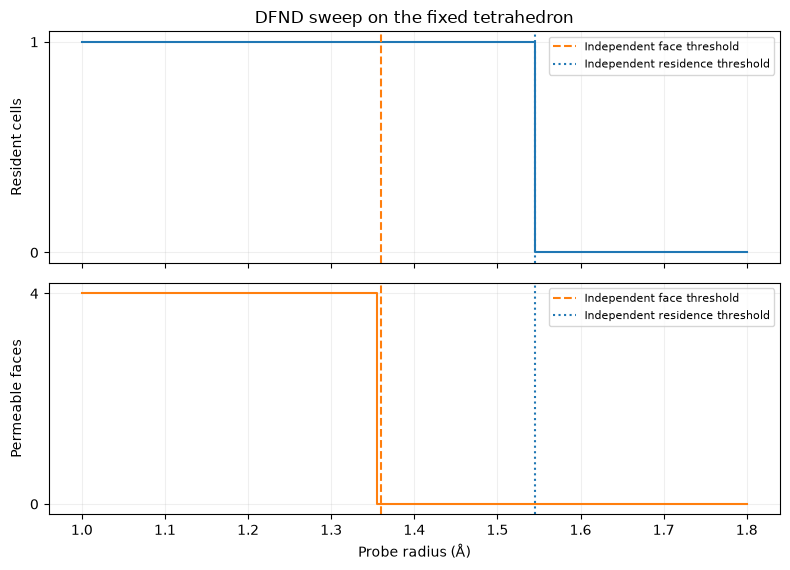

In [7]:
sweep = []
for probe in probe_sweep:
    observation, _ = observe(float(probe))
    margin = min(abs(probe-expected_face), abs(probe-expected_residence))
    if margin > 10*atol:
        assert observation['resident'] == bool(probe < expected_residence)
        assert observation['permeable_faces'] == (4 if probe < expected_face else 0)
    sweep.append({key: observation[key] for key in
                  ['probe_radius', 'resident', 'permeable_faces', 'family',
                   'raw_component_count', 'external_links']})
fig, axes = plt.subplots(2, 1, figsize=(8, 5.8), sharex=True)
axes[0].step(probe_sweep, [r['resident'] for r in sweep], where='mid', color='tab:blue')
axes[1].step(probe_sweep, [r['permeable_faces'] for r in sweep], where='mid', color='tab:orange')
for ax in axes:
    ax.axvline(expected_face, linestyle='--', color='tab:orange', label='Independent face threshold')
    ax.axvline(expected_residence, linestyle=':', color='tab:blue', label='Independent residence threshold')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.2)
axes[0].set(ylabel='Resident cells', yticks=[0, 1], title='DFND sweep on the fixed tetrahedron')
axes[1].set(xlabel='Probe radius (Å)', ylabel='Permeable faces', yticks=[0, 4])
fig.tight_layout()
plt.show()

## Reporting is a separate choice

Raising `min_size` to 2 excludes the one-node void from compatibility buckets,
while retaining the same raw component and geometry. This deliberate control
explains why an empty reported collection is not sufficient to diagnose a
geometric failure. All three principal experiments used `min_size=0`.

In [8]:
filtered, filtered_result = observe(1.4, min_size=2)
geometry_unchanged = (
    filtered_result['raw']['parameters']['result_key']
    == second_result['raw']['parameters']['result_key']
)
assert geometry_unchanged
assert filtered['raw_component_count'] == 1
assert sum(filtered['reported_counts'].values()) == 0
reporting_control = {
    'probe_radius': qrecord(1.4, 'angstroms', 'probe_radius'), 'min_size': 2,
    'raw_component_count': filtered['raw_component_count'],
    'reported_component_count': sum(filtered['reported_counts'].values()),
    'geometry_unchanged': geometry_unchanged,
}
display(Markdown(
    '| min_size | Raw wet components | Reported voids |\n|---:|---:|---:|\n'
    f"| 0 | {second['raw_component_count']} | {second['reported_counts']['voids']} |\n"
    f"| 2 | {filtered['raw_component_count']} | {filtered['reported_counts']['voids']} |"
))

| min_size | Raw wet components | Reported voids |
|---:|---:|---:|
| 0 | 1 | 1 |
| 2 | 1 | 0 |

## Volumes and conclusions

The finite hull volume agrees with the independent formula. The separate
`volume_solvent_estimate` field concerns a different modeled object and is an
estimate: its error is not certified here. In particular, it is not an exact
probe-accessible volume. The unchanged atomic input explains why a cell-level
bare-space estimate can persist when the probe becomes too large to reside.

The clearances and all three nonmarginal regimes pass their declared checks.
The sweep supports the expected transition ordering and the reporting control
separates raw geometry from filtered presentation. Volume precision,
general continuous-path validity, nonsymmetric geometries and biological
interpretation remain open, separately scoped questions.

Original-method comparisons are the next stage. The
[historical combined record](historical.ipynb) and its original artifacts remain
available; no third-party result has been refreshed by these notebooks.

In [9]:
display(Markdown(
    '| Probe (Å) | Finite hull (Å³) | Cell solvent estimate (Å³) |\n|---:|---:|---:|\n'
    + '\n'.join(
        f"| {probe:.1f} | {float(puw.get_value(decode(row['cell_hull_volume'], 'cell_hull_volume', 'angstroms**3'), to_unit='angstroms**3')):.9f} | "
        f"{float(puw.get_value(decode(row['solvent_volume_estimate'], 'solvent_volume_estimate', 'angstroms**3'), to_unit='angstroms**3')):.9f} |"
        for probe, row in zip(probes, anchors)
    )
))

| Probe (Å) | Finite hull (Å³) | Cell solvent estimate (Å³) |
|---:|---:|---:|
| 1.2 | 17.545322710 | 13.291911144 |
| 1.4 | 17.545322710 | 13.291911144 |
| 1.7 | 17.545322710 | 13.291911144 |

In [10]:
source_root = Path(tmt.__file__).parent
source_digest = hashlib.sha256()
source_files = sorted(source_root.rglob('*.py'))
for path in source_files:
    content = path.read_bytes()
    source_digest.update(path.relative_to(source_root).as_posix().encode() + b'\0')
    source_digest.update(str(len(content)).encode() + b'\0' + content)
native_report = {
    'schema': 'topomt.benchlab.dfnd-observations/1',
    'case_id': fixture['case_id'], 'case_version': fixture['case_version'],
    'input_sha256': hashlib.sha256(input_bytes).hexdigest(),
    'reference_sha256': hashlib.sha256(reference_bytes).hexdigest(),
    'software': {'python': platform.python_version(), **{
        name: version(name) for name in ['topomt', 'pyunitwizard', 'numpy', 'scipy', 'numba']
    }},
    'topomt_source': {'file_count': len(source_files), 'sha256': source_digest.hexdigest(),
                     'scope': 'Sorted topomt/**/*.py relative paths and length-delimited bytes'},
    'query': {'min_size': 0, 'transit_policy': 'with_connectors',
              'gate_intrusion_policy': 'flag_only', 'dry_adjacency': 'face',
              'residence_tolerance': qrecord(0.0, 'angstroms', 'residence_tolerance'),
              'permeability_tolerance': qrecord(0.0, 'angstroms', 'permeability_tolerance'),
              'epsilon': fixture['epsilon']},
    'clearances': {
        'residence_clearance': qrecord(observed_residence, 'angstroms', 'residence_clearance'),
        'face_clearance': qrecord(observed_faces, 'angstroms', 'face_clearance'),
    },
    'anchors': anchors, 'sweep': sweep, 'reporting_control': reporting_control,
    'reference_checks': 'passed',
    'limits': ['No original-provider execution in this stage', 'No exact solvent-volume claim',
               'No general continuous navigability or biological-site validation'],
}
text = json.dumps(native_report, indent=2, allow_nan=False)
display({'text/plain': text,
         'text/html': '<details><summary>Complete native observations</summary><pre>'
                      + html.escape(text) + '</pre></details>'}, raw=True)

{
  "schema": "topomt.benchlab.dfnd-observations/1",
  "case_id": "regular_tetrahedron",
  "case_version": 1,
  "input_sha256": "8634f70afdaf21cb8388887f5f80ae73dc36ef4f043198a10b525a93ebde5ce3",
  "reference_sha256": "cc60019cd121d352d1ddc9c700ec4c0684c43e3cfb229f721a11a368ecdabab3",
  "software": {
    "python": "3.14.10",
    "topomt": "0.5.0+387.gcf4d475.dirty",
    "pyunitwizard": "0.29.1+6.gf82b618",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "numba": "0.68.1"
  },
  "topomt_source": {
    "file_count": 267,
    "sha256": "bdab884fdc530c55fe99e8109720879dd8609da9b1f8764e937d1448da8e40d9",
    "scope": "Sorted topomt/**/*.py relative paths and length-delimited bytes"
  },
  "query": {
    "min_size": 0,
    "transit_policy": "with_connectors",
    "gate_intrusion_policy": "flag_only",
    "dry_adjacency": "face",
    "residence_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "residence_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:3ba2a05b6ed0bfc574a7a7c18c6a68e1"
    },
    "permeability_tolerance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "permeability_tolerance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 0.0,
      "block_digests": [
        "blake2b-128:589e43d024eb1b4ba623f81a50564bc8"
      ],
      "digest": "blake2b-128:5776c109ac89c18e2c9b62bf36990ac4"
    },
    "epsilon": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "epsilon",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [],
        "blocks": [
          1
        ]
      },
      "values": 1e-06,
      "block_digests": [
        "blake2b-128:fdc4aee404c6c8d3af6c444a146a42d5"
      ],
      "digest": "blake2b-128:afe0b5c20f12a97f318d2e509e8ae42b"
    }
  },
  "clearances": {
    "residence_clearance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "residence_clearance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [
          1
        ],
        "blocks": [
          1
        ]
      },
      "values": [
        1.5455739091877108
      ],
      "block_digests": [
        "blake2b-128:e5acadba832509bd5d3177f2a0b35df8"
      ],
      "digest": "blake2b-128:970ed54b7819affd8ca0f587e1adda0e"
    },
    "face_clearance": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "face_clearance",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [
          1,
          4
        ],
        "blocks": [
          4
        ]
      },
      "values": [
        [
          1.3599564267050157,
          1.3599564267050157,
          1.3599564267050157,
          1.3599564267050157
        ]
      ],
      "block_digests": [
        "blake2b-128:08a520385cf976dba2674c83dbb03721"
      ],
      "digest": "blake2b-128:ab6ae33f88130ea67db867baf468e904"
    }
  },
  "anchors": [
    {
      "probe_radius": {
        "manifest": {
          "format": "qrec/0.3",
          "field": "pr

Download the reviewed {download}`native observations <artifacts/native_study_v1/dfnd_observations.json>`
and {download}`independent reference <artifacts/native_study_v1/system_reference.json>`.
Rerunning this notebook displays a new report in memory and does not replace
those files. Return to [the case overview](index.md).